# 03. pandas 기본

* CSV 파일을 데이터프레임으로 불러와 **확인 → 통계 → 정렬 → 선택 → 가공 → 결측치 → 시각화** 흐름을 익힙니다.
* 앞서 배운 **Series·DataFrame** 개념이 실제 데이터에서 어떻게 쓰이는지 확인합니다.

> 📁 이 노트북은 **`data/scores.csv`** 파일을 사용합니다.
> 노트북과 같은 위치에 **`data`** 폴더를 만들고 그 안에 `scores.csv`를 넣어주세요.

In [2]:
import pandas as pd

## CSV 파일로 데이터프레임 생성
* **`pd.read_csv(파일경로)`**
    * 인덱스 라벨 : 기본은 0,1,2 … (RangeIndex)
    * 컬럼 라벨 : CSV의 첫 번째 행
    * 컬럼 자료형 : 자동 추론

In [3]:
# ----------------------------------------------------------
# 그냥 읽기 (학번이 정수로 인식됨)
# ----------------------------------------------------------

# 👉 여기에 코드를 작성하세요

df = pd.read_csv("data/scores.csv",
                 encoding='UTF-8',
                 dtype={"학번":str},
                 index_col="학번")
df

,이름,성별,국어,영어,수학
학번,,,,,
0001,kate,f,100.0,90,95.0
0002,olivia,f,90.0,80,75.0
0003,emma,f,95.0,100,100.0
0004,sophia,f,100.0,100,100.0
0005,amy,f,NaN,35,60.0
0006,james,m,70.0,75,65.0
0007,daniel,m,80.0,90,55.0
0008,peter,m,50.0,60,NaN
0009,kevin,m,100.0,100,90.0


In [ ]:
# ----------------------------------------------------------
# 옵션을 주어 읽기
#   - dtype     : 컬럼의 자료형 지정 (학번을 문자열로)
#   - index_col : 인덱스 라벨로 사용할 컬럼 지정
# ----------------------------------------------------------

# 👉 여기에 코드를 작성하세요

## 데이터프레임 확인

#### 미리보기
* `df.head(n)` : 상위 n개 (기본 5)
* `df.tail(n)` : 하위 n개 (기본 5)
* `df.sample(n)` : 랜덤 n개 (기본 1)

In [12]:

# 👉 여기에 코드를 작성하세요

df.head()

,이름,성별,국어,영어,수학
학번,,,,,
0001,kate,f,100.0,90,95.0
0002,olivia,f,90.0,80,75.0
0003,emma,f,95.0,100,100.0
0004,sophia,f,100.0,100,100.0
0005,amy,f,NaN,35,60.0


In [13]:

# 👉 여기에 코드를 작성하세요

df.tail()

,이름,성별,국어,영어,수학
학번,,,,,
0007,daniel,m,80.0,90,55.0
0008,peter,m,50.0,60,NaN
0009,kevin,m,100.0,100,90.0
0010,jack,m,90.0,95,70.0
0011,james,m,70.0,75,65.0


In [14]:

# 👉 여기에 코드를 작성하세요

df.sample()

,이름,성별,국어,영어,수학
학번,,,,,
0011,james,m,70.0,75,65.0


#### 정보 확인 : `df.info()`
* 인덱스 종류·범위, 컬럼 개수, **Null 여부**, 컬럼별 자료형, 메모리 사용량을 한눈에

In [15]:

# 👉 여기에 코드를 작성하세요

df.info()

<class 'pandas.DataFrame'>
Index: 11 entries, 0001 to 0011
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   이름      11 non-null     str    
 1   성별      11 non-null     str    
 2   국어      10 non-null     float64
 3   영어      11 non-null     int64  
 4   수학      10 non-null     float64
dtypes: float64(2), int64(1), str(2)
memory usage: 528.0+ bytes


#### 주요 속성
* `df.shape` : (행, 열) 튜플
* `df.columns` : 컬럼 라벨
* `df.index` : 인덱스 라벨
* `df.dtypes` : 컬럼별 자료형

In [19]:

# 👉 여기에 코드를 작성하세요

df.dtypes

이름        str
성별        str
국어    float64
영어      int64
수학    float64
dtype: object

> 💡 **참고** — 가끔 쓰는 속성
> * `df.values` : 값 전체를 넘파이 배열로
> * `df.size` : 전체 원소 수 (행×열)
> * `df.T` : 전치(행↔열 바꾸기)

In [ ]:
# 참고용 : 필요할 때만 사용

# 👉 여기에 코드를 작성하세요

df.T

학번,0001,0002,0003,0004,0005,0006,0007,0008,0009,0010,0011
이름,kate,olivia,emma,sophia,amy,james,daniel,peter,kevin,jack,james
성별,f,f,f,f,f,m,m,m,m,m,m
국어,100.0,90.0,95.0,100.0,NaN,70.0,80.0,50.0,100.0,90.0,70.0
영어,90,80,100,100,35,75,90,60,100,95,75
수학,95.0,75.0,100.0,100.0,60.0,65.0,55.0,NaN,90.0,70.0,65.0


## 데이터 통계
* 전체 요약통계 : `df.describe()` (숫자형 컬럼만, NaN은 무시)
* 컬럼별 통계 : `df['컬럼'].mean()`, `.min()`, `.max()`, `.median()`, `.std()` …

In [22]:

# 👉 여기에 코드를 작성하세요

df.describe()

,국어,영어,수학
count,10.000000,11.000000,10.000000
mean,84.500000,81.818182,77.500000
std,16.741499,20.158463,17.199806
min,50.000000,35.000000,55.000000
25%,72.500000,75.000000,65.000000
50%,90.000000,90.000000,72.500000
75%,98.750000,97.500000,93.750000
max,100.000000,100.000000,100.000000


In [26]:
# 국어 점수의 평균 (NaN은 무시하고 계산)

# 👉 여기에 코드를 작성하세요

df["국어"].mean()
# df.loc[:,"국어"]

np.float64(84.5)

## 빈도수
* 범주형 데이터의 값별 개수 : `df['컬럼'].value_counts()`

In [28]:
# 성별 빈도수

# 👉 여기에 코드를 작성하세요

df['성별'].value_counts()

성별
m    6
f    5
Name: count, dtype: int64

## 정렬
* `df.sort_values(by='컬럼')` : 값으로 정렬
* `df.sort_index()` : 인덱스로 정렬
* 옵션 `ascending=False` : 내림차순

In [ ]:
# 국어 점수 오름차순

# 👉 여기에 코드를 작성하세요

df['국어'].sort_values()

학번
0001    100.0
0004    100.0
0009    100.0
0003     95.0
0002     90.0
0010     90.0
0007     80.0
0006     70.0
0011     70.0
0008     50.0
0005      NaN
Name: 국어, dtype: float64

In [32]:
# 국어 점수 내림차순

# 👉 여기에 코드를 작성하세요

df['국어'].sort_values(ascending=False)

학번
0001    100.0
0004    100.0
0009    100.0
0003     95.0
0002     90.0
0010     90.0
0007     80.0
0006     70.0
0011     70.0
0008     50.0
0005      NaN
Name: 국어, dtype: float64

## 데이터 선택

### 컬럼 선택
* `df['컬럼']` → **Series**
* `df[['컬럼']]` → **DataFrame**
* `df[['컬럼1','컬럼2']]` → 여러 컬럼

In [33]:
# '이름' 컬럼 → Series

# 👉 여기에 코드를 작성하세요

df[['이름']]

,이름
학번,
0001,kate
0002,olivia
0003,emma
0004,sophia
0005,amy
0006,james
0007,daniel
0008,peter
0009,kevin


In [34]:
# '이름','국어' 컬럼 → DataFrame

# 👉 여기에 코드를 작성하세요

df[['이름','국어']]

,이름,국어
학번,,
0001,kate,100.0
0002,olivia,90.0
0003,emma,95.0
0004,sophia,100.0
0005,amy,NaN
0006,james,70.0
0007,daniel,80.0
0008,peter,50.0
0009,kevin,100.0


### 라벨로 선택 : `df.loc[행, 열]`
* 행·열을 **라벨**로 지정 (라벨 슬라이스는 끝 포함)

In [37]:
# 학번 0001 학생의 전체 데이터

# 👉 여기에 코드를 작성하세요

df.loc['0001',:]

이름     kate
성별        f
국어    100.0
영어       90
수학     95.0
Name: 0001, dtype: object

In [47]:
# 학번 0001~0003 학생의 국어~수학 점수

# 👉 여기에 코드를 작성하세요

df.loc['0001':'0003','국어':'수학']

,국어,영어,수학
학번,,,
0001,100.0,90,95.0
0002,90.0,80,75.0
0003,95.0,100,100.0


In [ ]:
# 학번 0001, 0005 학생의 이름, 수학

# 👉 여기에 코드를 작성하세요

df.loc[:'0005',['이름','수학']]
# df.iloc[0:5,[0,4]]

,이름,수학
학번,,
0001,kate,95.0
0002,olivia,75.0
0003,emma,100.0
0004,sophia,100.0
0005,amy,60.0


### 정수 위치로 선택 : `df.iloc[행, 열]`
* 행·열을 **정수 위치**로 지정 (슬라이스는 끝 미포함, 파이썬과 동일)

In [ ]:
# 0번째 행

# 👉 여기에 코드를 작성하세요

In [ ]:
# 0~2번째 행의 마지막 열

# 👉 여기에 코드를 작성하세요

### 조건으로 선택 : `df.loc[조건]`
* 비교연산 : `>`, `<`, `>=`, `<=`, `==`, `!=`
* 논리연산 : `&`(and), `|`(or), `~`(not) — 각 조건은 **소괄호로** 묶기
* 멤버연산 : `.isin([값들])`
* 결측치 : `.isnull()`, `.notnull()`

In [86]:
# 국어 점수가 100점인 학생

# 👉 여기에 코드를 작성하세요

cond = df['국어'] == 100
df.loc[cond,:]

,이름,성별,국어,영어,수학
학번,,,,,
0001,kate,f,100.0,90,95.0
0004,sophia,f,100.0,100,100.0
0009,kevin,m,100.0,100,90.0


In [127]:
# 국어·영어·수학 모두 100점인 학생

# 👉 여기에 코드를 작성하세요

cond1 = df['국어']==100
cond2 = df['영어']==100
cond3 = df['수학']==100
df.loc[cond1 & cond2 & cond3]

,이름,성별,국어,영어,수학
학번,,,,,
0004,sophia,f,100.0,100,100.0


In [ ]:
# 국어 점수가 null인 학생

# 👉 여기에 코드를 작성하세요

In [113]:
# 수학점수가 70점 이상인 남학생의 이름, 성별, 수학

cond = (df['수학'] >= 70) & (df['성별'] == 'm')
cond

df.loc[cond,['이름','성별','수학']]

,이름,성별,수학
학번,,,
0009,kevin,m,90.0
0010,jack,m,70.0


## 열 추가 / 삭제

#### 파생컬럼 추가
* **`df['새컬럼'] = 데이터`** (컬럼이 없으면 추가, 있으면 수정)
* 컬럼 간 연산에서 **NaN이 있으면 결과도 NaN** (전파)
* 단, `mean()` 같은 집계함수는 NaN을 무시하고 계산

In [12]:
# 국어~수학의 평균을 '평균' 컬럼으로 추가

# 👉 여기에 코드를 작성하세요

df['평균'] = df.loc[:,'국어':'수학'].mean(axis=1).round(2)
df['순위'] = df['평균'].rank(ascending=False).astype(int)
df

,이름,성별,국어,영어,수학,평균,순위
학번,,,,,,,
0001,kate,f,100.0,90,95.0,95.00,4
0002,olivia,f,90.0,80,75.0,81.67,6
0003,emma,f,95.0,100,100.0,98.33,2
0004,sophia,f,100.0,100,100.0,100.00,1
0005,amy,f,NaN,35,60.0,47.50,11
0006,james,m,70.0,75,65.0,70.00,8
0007,daniel,m,80.0,90,55.0,75.00,7
0008,peter,m,50.0,60,NaN,55.00,10
0009,kevin,m,100.0,100,90.0,96.67,3


#### 열 삭제
* `df.drop('컬럼', axis=1)`

In [15]:
# 순위 컬럼 삭제

# 👉 여기에 코드를 작성하세요

df = df.drop('순위', axis=1)
df

,이름,성별,국어,영어,수학,평균
학번,,,,,,
0001,kate,f,100.0,90,95.0,95.00
0002,olivia,f,90.0,80,75.0,81.67
0003,emma,f,95.0,100,100.0,98.33
0004,sophia,f,100.0,100,100.0,100.00
0005,amy,f,NaN,35,60.0,47.50
0006,james,m,70.0,75,65.0,70.00
0007,daniel,m,80.0,90,55.0,75.00
0008,peter,m,50.0,60,NaN,55.00
0009,kevin,m,100.0,100,90.0,96.67


## 결측치 처리

#### 결측치 확인
* 컬럼별 결측치 개수 : `df.isnull().sum()`

In [18]:

# 👉 여기에 코드를 작성하세요

df.isnull().sum()


이름    0
성별    0
국어    1
영어    0
수학    1
평균    0
dtype: int64

#### 결측치 삭제
* `df.dropna()` : 결측치가 있는 **행 전체** 삭제
* `df.dropna(subset=['컬럼'])` : 특정 컬럼에 결측이 있는 행만 삭제

In [21]:
# 결측치가 있는 행 삭제 (결과만 확인 → 원본 df는 그대로)

# 👉 여기에 코드를 작성하세요

df.dropna()
# df

,이름,성별,국어,영어,수학,평균
학번,,,,,,
0001,kate,f,100.0,90,95.0,95.00
0002,olivia,f,90.0,80,75.0,81.67
0003,emma,f,95.0,100,100.0,98.33
0004,sophia,f,100.0,100,100.0,100.00
0006,james,m,70.0,75,65.0,70.00
0007,daniel,m,80.0,90,55.0,75.00
0009,kevin,m,100.0,100,90.0,96.67
0010,jack,m,90.0,95,70.0,85.00
0011,james,m,70.0,75,65.0,70.00


#### 이웃 값으로 채우기
* `df.ffill()` : 이전(위) 값으로 채우기
* `df.bfill()` : 다음(아래) 값으로 채우기

In [24]:
# 이전 값으로 채우기 (원본은 그대로)

# 👉 여기에 코드를 작성하세요

df.ffill()

,이름,성별,국어,영어,수학,평균
학번,,,,,,
0001,kate,f,100.0,90,95.0,95.00
0002,olivia,f,90.0,80,75.0,81.67
0003,emma,f,95.0,100,100.0,98.33
0004,sophia,f,100.0,100,100.0,100.00
0005,amy,f,100.0,35,60.0,47.50
0006,james,m,70.0,75,65.0,70.00
0007,daniel,m,80.0,90,55.0,75.00
0008,peter,m,50.0,60,55.0,55.00
0009,kevin,m,100.0,100,90.0,96.67


#### 컬럼별로 다른 값 채우기
* `df.fillna({'컬럼1':값1, '컬럼2':값2})`
* 예: 국어는 평균으로, 수학은 0으로

In [27]:
# 국어는 평균, 수학은 0으로 채우기 (원본은 그대로)

# 👉 여기에 코드를 작성하세요

df = df.fillna(0)
df['국어'] = df['국어'].astype(int)
df['수학'] = df['수학'].astype(int)
df['평균'] = df.loc[:,'국어':'수학'].mean(axis=1).round(2)
df

,이름,성별,국어,영어,수학,평균
학번,,,,,,
0001,kate,f,100,90,95,95.00
0002,olivia,f,90,80,75,81.67
0003,emma,f,95,100,100,98.33
0004,sophia,f,100,100,100,100.00
0005,amy,f,0,35,60,31.67
0006,james,m,70,75,65,70.00
0007,daniel,m,80,90,55,75.00
0008,peter,m,50,60,0,36.67
0009,kevin,m,100,100,90,96.67


#### 결측치를 0으로 채우기 (원본에 반영)
* 재할당으로 **원본 df에 반영**합니다. (뒤의 astype(int)를 위해 결측치를 없앰)

In [ ]:
# 최종: 0으로 채워 원본에 반영

# 👉 여기에 코드를 작성하세요

## 자료형 변경
* `df.astype({'컬럼': '자료형'})`
* `df['컬럼'].astype('자료형')`

In [ ]:
# 국어, 수학 컬럼을 정수형으로 변경

# 👉 여기에 코드를 작성하세요

## 시각화
* `df.plot()`
    * 기본 그래프 : 선그래프 / x축 : 인덱스 / y축 : 숫자형 컬럼
* 주요 옵션 : `kind`(종류), `x`, `y`, `figsize`(크기), `title`(제목), `color`(색)

#### 한글 폰트 설정
* matplotlib의 **기본 폰트에는 한글 글자 모양이 없어서**, 한글을 그리면 네모(□)로 깨집니다.
* 그래서 그래프를 그리기 전에 **한글이 들어있는 폰트로 기본값을 바꿔줘야** 합니다.
* 폰트는 운영체제마다 이름이 달라서(윈도우 `Malgun Gothic`, 맥 `AppleGothic`, 리눅스·코랩 `NanumGothic`),
  아래 셀은 **실행 중인 OS를 자동으로 감지**해 알맞은 폰트를 지정합니다.

> 💡 **`plt.rc('그룹', 키=값)`** 은 matplotlib의 **전역 기본 설정**(`rcParams`)을 바꾸는 함수입니다.
> (`rc` = runtime configuration, 실행 환경 설정)
> * `plt.rc('font', family='...')` → 앞으로 그리는 **모든 그래프의 기본 글꼴**을 지정 (한 번만 실행하면 계속 적용)
> * `plt.rc('axes', unicode_minus=False)` → **음수 기호(−)** 를 일반 하이픈(-)으로 처리.
>   한글 폰트엔 유니코드 마이너스 글자가 없는 경우가 많아, 이 줄이 없으면 음수가 네모로 깨집니다.
>   그래서 한글 폰트 설정과 거의 **항상 세트**로 씁니다.

In [28]:
# ------------------------------------------------
# 한글 폰트 자동 설정 (환경에 맞게 알아서 선택)
# ------------------------------------------------
import platform
import matplotlib.pyplot as plt

system = platform.system()   # 실행 중인 OS 이름 반환
if system == 'Windows':
    plt.rc('font', family='Malgun Gothic')      # 윈도우
elif system == 'Darwin':                        # Darwin = macOS(맥)
    plt.rc('font', family='AppleGothic')        # 맥
else:
    plt.rc('font', family='NanumGothic')        # 리눅스·코랩
    # 코랩에서 폰트가 없다면 아래 한 줄을 먼저 실행하세요
    # !apt -qq install fonts-nanum && rm -rf ~/.cache/matplotlib

plt.rc('axes', unicode_minus=False)             # 음수 기호(-) 깨짐 방지

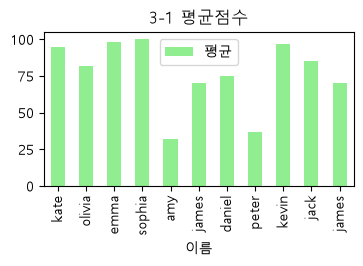

In [40]:
# ------------------------------
# 국어 점수 막대그래프
#  - kind='bar', x=이름, y=국어
# ------------------------------

# 👉 여기에 코드를 작성하세요

df.plot(kind='bar', x='이름', y='평균', figsize=(4,2), title="3-1 평균점수", color='lightgreen');

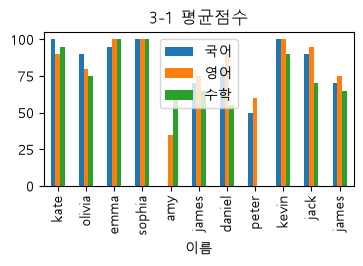

In [41]:
# ------------------------------
# 학생별 국어·영어·수학 막대그래프
# ------------------------------

# 👉 여기에 코드를 작성하세요

df.plot(kind='bar', x='이름', y=["국어","영어","수학"], figsize=(4,2), title="3-1 평균점수");